# 06 · Chuva da bacia (NASA GPM IMERG)

O IMERG Final diário (`GPM_3IMERGDF`, V07) é global: cada arquivo tem ~117 MB e grade 0,1° (3600 × 1800). O fluxo é
**baixar um mês → recortar pela bacia e tirar a média → apagar o bruto → guardar só o CSV**. O código está em `src/imerg.py`.

Este notebook faz (1) um teste de sanidade com os arquivos que você já baixou e (2) confere o CSV final.

In [1]:
import sys
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config, imerg
plt.rcParams["figure.figsize"] = (11, 3.4); plt.rcParams["axes.grid"] = True

## 1. Teste com os arquivos já baixados em `data/raw/imerg/`
Média sobre a caixa retangular da bacia (sem polígono ainda, então o valor é *diluído*: inclui áreas fora do Taquari-Antas).

In [2]:
arquivos = sorted(p for p in config.RAW.glob("imerg/*") if p.suffix in (".nc4", ".nc"))
print(len(arquivos), "arquivo(s)")
linhas = []
for f in arquivos:
    dia, media, n = imerg.basin_mean(f)               # sem geom -> caixa BBOX
    linhas.append({"dia": dia.date(), "chuva_media_mm_dia": round(media, 1), "celulas": n, "arquivo": f.name})
pd.DataFrame(linhas)

3 arquivo(s)


,dia,chuva_media_mm_dia,celulas,arquivo
0,2023-09-03,45.8,532,3B-DAY.MS.MRG.3IMERG.20230903-S000000-E235959....
1,2023-09-04,108.9,532,3B-DAY.MS.MRG.3IMERG.20230904-S000000-E235959....
2,2023-09-05,0.4,532,3B-DAY.MS.MRG.3IMERG.20230905-S000000-E235959....


**Como conferir:** em 3–5/set/2023 a chuva na região foi extrema; esperamos valores bem acima do normal (dezenas de mm/dia na média da caixa).
Se vier ~0 ou `NaN` em todos os dias, algo está errado (me mande a saída).

## 2. Rodar para o período todo (no **terminal**, não no notebook)

Leva um bom tempo (milhares de arquivos), então rode no terminal do Ubuntu, na raiz do projeto, e deixe aberto. É **retomável**: se interromper (Ctrl+C) ou der erro, rode o mesmo comando e ele continua.

```bash
cd ~/projetos/capstone
conda activate capstone
python -m src.imerg --start 2015-01-01 --end 2026-06-30
```

Quando você tiver o polígono da bacia (GeoPackage/GeoJSON em EPSG:4326 ou outro; ele reprojeta), acrescente `--basin data/raw/bacia_taquari_antas.gpkg`.
A cada mês concluído ele imprime `ano-mês: N/N dias em Xs`. Para testar antes, use um período curto, por exemplo `--start 2023-09-01 --end 2023-09-30`.

## 3. Conferir o CSV gerado

120 dias | 2015-01-01 -> 2015-04-30 | faltando: 0


count    120.00
mean       4.82
std        8.84
min        0.00
25%        0.04
50%        0.73
75%        6.08
max       61.30
Name: chuva_bacia_mm, dtype: float64

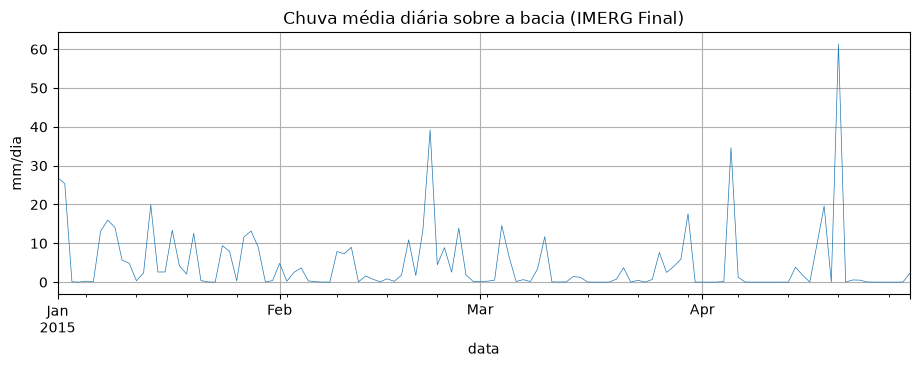

Dias mais chuvosos:


data
2015-04-20    61.3
2015-02-22    39.2
2015-04-05    34.6
2015-01-01    26.9
2015-01-02    25.4
2015-01-14    19.9
2015-04-18    19.6
2015-03-30    17.6
Name: chuva_bacia_mm, dtype: float64

In [4]:
csv = config.PROCESSED / "chuva_bacia_diaria.csv"
if not csv.exists():
    print("Ainda não existe:", csv)
else:
    chuva = pd.read_csv(csv, parse_dates=["data"], index_col="data")["chuva_bacia_mm"]
    print(len(chuva), "dias |", chuva.index.min().date(), "->", chuva.index.max().date(), "| faltando:", int(chuva.isna().sum()))
    display(chuva.describe().round(2))
    fig, ax = plt.subplots(); chuva.plot(ax=ax, lw=0.5); ax.set_ylabel("mm/dia"); ax.set_title("Chuva média diária sobre a bacia (IMERG Final)")
    plt.show()
    print("Dias mais chuvosos:"); display(chuva.nlargest(8).round(1))

## 4. O que fazer com isso
- Comparar com a chuva das **estações da ANA** (validação do satélite, uma figura para o artigo).
- Usar como feature `chuva_bacia` (acumulados de 1–3 dias) no modelo.
- **Registrar na metodologia:** produto, versão, DOI e data de download; dia em UTC (IMERG) × dia local (níveis);
  e a limitação de menor acerto do IMERG em relevo complexo (Serra Gaúcha).